# This notebook demonstrates a series of experiments conducted with SCAg on the CASPER dataset

# Step 0. Setup the experiment

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import json
import numpy as np
import pandas as pd

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from ignite.metrics import Accuracy, Precision, Recall, Loss, ClassificationReport, ConfusionMatrix
from ignite.engine import create_supervised_evaluator

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 6) 

In [5]:
from scag.models import ParametrizedMLP, ParametrizedCNN, ParametrizedTransformer
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
models_path = os.path.join('models', 'scag')
batch_size = 256

In [6]:
metrics = {
    'accuracy': Accuracy(),
    'precision': Precision(average='macro'),
    'recall': Recall(average='macro'),
    'loss': Loss(nn.CrossEntropyLoss()),
    'report': ClassificationReport(),
    # 2Hz, 10Hz, Acc_Gyro_20Hz, earthquake, hitting, magnet (6 classes)
    'confusion': ConfusionMatrix(num_classes=6),
}

## Function to pretty print classification reports

In [7]:
# the CASPER dataset
mapping = {
    '0': '2Hz',
    '1': '10Hz',
    '2': 'Acc_Gyro_20Hz',
    '3': 'earthquake',
    '4': 'hitting',
    '5': 'magnet',
}

def create_and_show_classification_report(data):
    # swapping 0-5 with actual label names
    data = {mapping.get(k, k): v for k, v in data.items()}

    data_df = pd.DataFrame(data).transpose()
    print(f'Classification report:\n{data_df}')

## Function to show beatiful figure of confusion matrix

In [8]:
def create_and_show_confusion_matrix(data):
    sns.heatmap(
        data, 
        annot=True,
        fmt='d',
        cmap='Blues',
        linewidths=0.5,
        linecolor='gray',
        cbar=True,
        xticklabels=[mapping[str(i)] for i in range(data.shape[1])],
        yticklabels=[mapping[str(i)] for i in range(data.shape[0])]
    )

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix', fontweight='bold')
    plt.tight_layout() 
    plt.show()

# Step 1. Load models

Connected with Table 4, classification models MLP-2, CNN-2, Transformer-1

## Pretrained MLP-2

In [9]:
with open(os.path.join(models_path, 'MLP-2.json')) as f:
    mlp2_params = json.load(f)

mlp2 = ParametrizedMLP(**mlp2_params).to(device)

mlp2_checkpoint = torch.load(os.path.join(models_path, 'MLP-2.pt'), map_location=device)
mlp2.load_state_dict(mlp2_checkpoint)

print(mlp2)

ParametrizedMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=720, out_features=224, bias=True)
    (1): BatchNorm1d(224, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.21365943293079284, inplace=False)
    (4): Linear(in_features=224, out_features=112, bias=True)
    (5): BatchNorm1d(112, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): Dropout(p=0.21365943293079284, inplace=False)
    (8): Linear(in_features=112, out_features=6, bias=True)
  )
)


## Pretrained CNN-2

In [10]:
with open(os.path.join(models_path, 'CNN-2.json')) as f:
    cnn2_params = json.load(f)

cnn2 = ParametrizedCNN(**cnn2_params).to(device)

cnn2_checkpoint = torch.load(os.path.join(models_path, 'CNN-2.pt'), map_location=device)
cnn2.load_state_dict(cnn2_checkpoint)

print(cnn2)

ParametrizedCNN(
  (features): Sequential(
    (0): Conv2d(1, 160, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): BatchNorm2d(160, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.11422333930462238, inplace=False)
    (5): Conv2d(160, 80, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (6): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.11422333930462238, inplace=False)
    (10): Conv2d(80, 40, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (11): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14):

## Pretrained Transformer-1

In [11]:
with open(os.path.join(models_path, 'Transformer-1.json')) as f:
    transformer1_params = json.load(f)

transformer1 = ParametrizedTransformer(**transformer1_params).to(device)

transformer1_checkpoint = torch.load(os.path.join(models_path, 'Transformer-1.pt'), map_location=device)
transformer1.load_state_dict(transformer1_checkpoint)

print(transformer1)

ParametrizedTransformer(
  (input_projection): Linear(in_features=24, out_features=32, bias=True)
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=32, bias=True)
        (dropout): Dropout(p=0.12934191784481877, inplace=False)
        (linear2): Linear(in_features=32, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.12934191784481877, inplace=False)
        (dropout2): Dropout(p=0.12934191784481877, inplace=False)
      )
    )
  )
  (final_dropout): Dropout(p=0.1694768061450053, inplace=False)
  (classifier): Linear(in_features=32, out_features=6, bias=True)
)


# Step 2. Validate pretrained models

Connected with Table 4, classification models MLP-2, CNN-2, Transformer-1

## Validation dataset

Please note that a reduced-size version of the dataset was utilized to comply with the repository's size constraints. Consequently, the reported metrics may exhibit slight deviations from those obtained on the full dataset.

In [12]:
X_valid = np.load(os.path.join('data', 'c-scag', 'Xr_valid.npy'))
y_valid = np.load(os.path.join('data', 'c-scag', 'yr_valid.npy'))
print(f'X_valid: {X_valid.shape}, y_valid: {y_valid.shape}' )

Xv_tensor = torch.tensor(X_valid, dtype=torch.float32).to(device)
yv_tensor = torch.tensor(y_valid, dtype=torch.long).to(device)

dataset_valid = TensorDataset(Xv_tensor, yv_tensor)
loader_valid = DataLoader(dataset_valid, batch_size=batch_size)

# 2-dimensional CNN
Xv_tensor_cnn = Xv_tensor.unsqueeze(1)
dataset_valid_cnn = TensorDataset(Xv_tensor_cnn, yv_tensor)
loader_valid_cnn = DataLoader(dataset_valid_cnn, batch_size=batch_size)

X_valid: (18060, 30, 24), y_valid: (18060,)


## MLP-2 validation

In [17]:
mlp2_evaluator = create_supervised_evaluator(mlp2, metrics=metrics, device=device)
mlp2_evaluator.run(loader_valid)
mlp2_metrics_valid = mlp2_evaluator.state.metrics.copy()

for key, value in mlp2_metrics_valid.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.987873754152824
precision: 0.9811972786955255
recall: 0.9818165310835502
loss: 0.03714494842495501


## CNN-2 validation

In [13]:
cnn2_evaluator = create_supervised_evaluator(cnn2, metrics=metrics, device=device)
cnn2_evaluator.run(loader_valid_cnn)
cnn2_metrics_valid = cnn2_evaluator.state.metrics.copy()

for key, value in cnn2_metrics_valid.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.9904208194905869
precision: 0.9903488283195498
recall: 0.9840283378265086
loss: 0.03757236687711967


## Transformer-1 validation

In [14]:
transformer1_evaluator = create_supervised_evaluator(transformer1, metrics=metrics, device=device)
transformer1_evaluator.run(loader_valid)
transformer1_metrics_valid = transformer1_evaluator.state.metrics.copy()

for key, value in transformer1_metrics_valid.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.9862679955703212
precision: 0.9798028760741514
recall: 0.9789255105355199
loss: 0.05481262882946602


Step 3. Test pretrained models on real data

(connected with Table 6, the CASPER dataset)

## Test dataset

Please note that a reduced-size version of the dataset was utilized to comply with the repository's size constraints. Consequently, the reported metrics may exhibit deviations from those obtained on the full dataset.

In [15]:
X_test = np.load(os.path.join('data', 'c-scag', 'Xr_test.npy'))
y_test = np.load(os.path.join('data', 'c-scag', 'yr_test.npy'))
print(f'X_test: {X_test.shape}, y_test: {y_test.shape}' )

Xt_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
yt_tensor = torch.tensor(y_test, dtype=torch.long).to(device)

dataset_test = TensorDataset(Xt_tensor, yt_tensor)
loader_test = DataLoader(dataset_test, batch_size=batch_size)

# 2-dimensional CNN
Xt_tensor_cnn = Xt_tensor.unsqueeze(1)
dataset_test_cnn = TensorDataset(Xt_tensor_cnn, yt_tensor)
loader_test_cnn = DataLoader(dataset_test_cnn, batch_size=batch_size)

X_test: (21158, 30, 24), y_test: (21158,)


## MLP-2 testing

accuracy: 0.9768881746856981
loss: 0.07280594681237593

Classification report:
               precision    recall  f1-score
2Hz             0.999251  1.000000  0.999625
10Hz            0.997258  1.000000  0.998627
Acc_Gyro_20Hz   0.993295  1.000000  0.996636
earthquake      0.966344  0.858243  0.909091
hitting         0.914480  0.975750  0.944122
magnet          0.994114  0.973220  0.983556
macro avg       0.977457  0.967869  0.971943


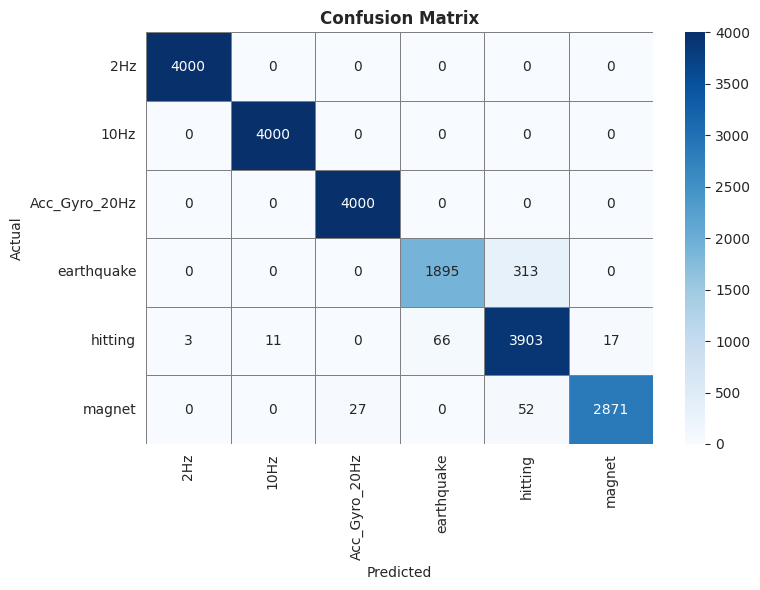

In [18]:
mlp2_evaluator.run(loader_test)
mlp2_metrics_test = mlp2_evaluator.state.metrics.copy()

for key, value in mlp2_metrics_test.items():
    print(f'{key}: {value}') if key in ['accuracy', 'loss'] else None
print()

mlp1_cr_test = json.loads(mlp2_metrics_test["report"])
create_and_show_classification_report(mlp1_cr_test)

mlp1_cm_test = mlp2_metrics_test["confusion"].numpy()
create_and_show_confusion_matrix(mlp1_cm_test)

## CNN-2 testing

accuracy: 0.9778807070611589
loss: 0.0738198550507639

Classification report:
               precision    recall  f1-score
2Hz             0.998752  1.000000  0.999375
10Hz            0.977517  1.000000  0.988631
Acc_Gyro_20Hz   0.985461  0.999750  0.992554
earthquake      0.996675  0.950181  0.972873
hitting         0.935329  0.976250  0.955352
magnet          0.987147  0.911186  0.947647
macro avg       0.980147  0.972895  0.976072


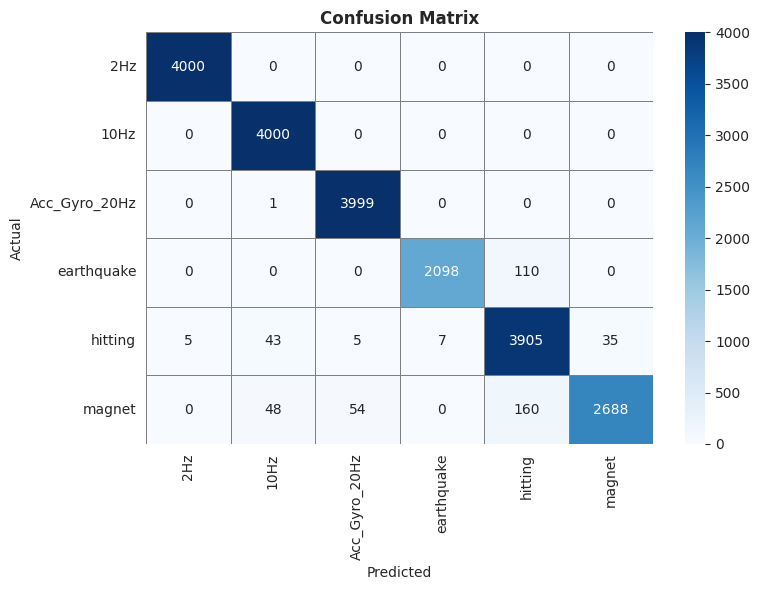

In [19]:
cnn2_evaluator.run(loader_test_cnn)
cnn2_metrics_test = cnn2_evaluator.state.metrics.copy()

for key, value in cnn2_metrics_test.items():
    print(f'{key}: {value}') if key in ['accuracy', 'loss'] else None
print()

cnn2_cr_test = json.loads(cnn2_metrics_test["report"])
create_and_show_classification_report(cnn2_cr_test)

cnn2_cm_test = cnn2_metrics_test["confusion"].numpy()
create_and_show_confusion_matrix(cnn2_cm_test)

## Transformer-1 testing

accuracy: 0.9821344172417052
loss: 0.06809092762452441

Classification report:
               precision    recall  f1-score
2Hz             0.999001  1.000000  0.999500
10Hz            0.997257  0.999750  0.998502
Acc_Gyro_20Hz   0.973473  1.000000  0.986558
earthquake      0.963081  0.956975  0.960018
hitting         0.960968  0.972500  0.966700
magnet          0.994629  0.941695  0.967439
macro avg       0.981402  0.978487  0.979786


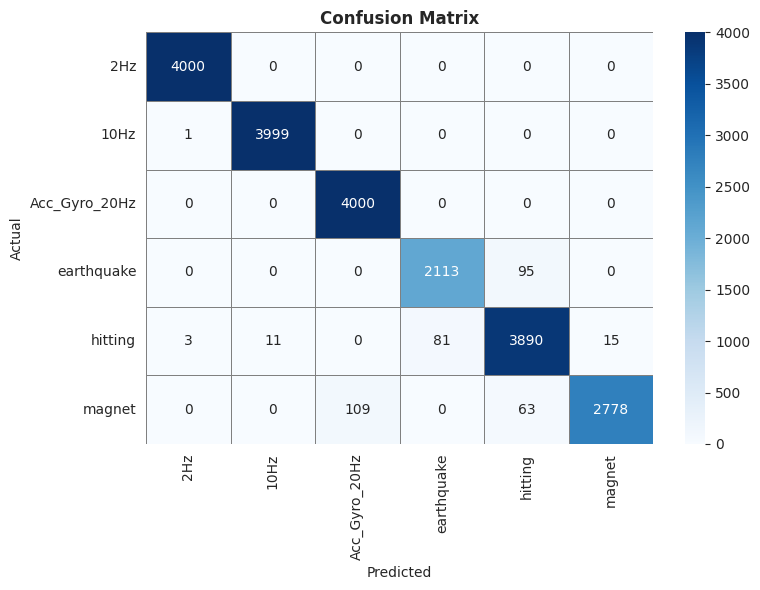

In [20]:
transformer1_evaluator.run(loader_test)
transformer1_metrics_test = transformer1_evaluator.state.metrics.copy()

for key, value in transformer1_metrics_test.items():
    print(f'{key}: {value}') if key in ['accuracy', 'loss'] else None
print()

transformer1_cr_test = json.loads(transformer1_metrics_test["report"])
create_and_show_classification_report(transformer1_cr_test)

transformer1_cm_test = transformer1_metrics_test["confusion"].numpy()
create_and_show_confusion_matrix(transformer1_cm_test)

# Step 4. Test pretrained models on predicted data

Connected with Table 8, the CASPER dataset

## Predicted datasets by models GRU-1, GRU2 and LSTM-2

Please note that a reduced-size version of the dataset was utilized to comply with the repository's size constraints. Consequently, the reported metrics may exhibit deviations from those obtained on the full dataset.

In [21]:
datasets = {'X': {}, 'y': {}, 'Xt': {}, 'yt': {}, 'd': {}, 'l': {}, 'l_cnn': {}}
X_names = ["GRU-1_Xr_pred", "GRU-2_Xr_pred", "LSTM-2_Xr_pred"]
y_names = ["GRU-1_yr_pred", "GRU-2_yr_pred", "LSTM-2_yr_pred"]
d_names = ["GRU-1_pred_dataset", "GRU-2_pred_dataset", "LSTM-2_pred_dataset"]
l_names = ["GRU-1_pred_loader", "GRU-2_pred_loader", "LSTM-2_pred_loader"]
l_cnn_names = ["GRU-1_pred_loader_cnn", "GRU-2_pred_loader_cnn", "LSTM-2_pred_loader_cnn"]

for X_name, y_name, dataset_name, loader_name, loader_cnn_name in zip(
    X_names, y_names, d_names, l_names, l_cnn_names
):
    datasets['X'][X_name] = np.load(os.path.join('data', 'p-scag', f"{X_name}.npy"))
    datasets['y'][y_name] = np.load(os.path.join('data', 'p-scag', f"{y_name}.npy"))
    print(f"{X_name}: {datasets['X'][X_name].shape}, {y_name}: {datasets['y'][y_name].shape}")
    
    datasets['Xt'][X_name] = torch.tensor(datasets['X'][X_name], dtype=torch.float32).to(device)
    datasets['yt'][y_name] = torch.tensor(datasets['y'][y_name], dtype=torch.long).to(device)
    
    datasets['d'][dataset_name] = TensorDataset(datasets['Xt'][X_name], datasets['yt'][y_name])
    datasets['l'][loader_name] = DataLoader(datasets['d'][dataset_name], batch_size=batch_size)
    
    datasets['Xt'][X_name] = datasets['Xt'][X_name].unsqueeze(1)
    datasets['d'][dataset_name] = TensorDataset(datasets['Xt'][X_name], datasets['yt'][y_name])
    datasets['l_cnn'][loader_cnn_name] = DataLoader(datasets['d'][dataset_name], batch_size=batch_size)
    
(GRU1_loader_pred, GRU2_loader_pred, LSTM2_loader_pred) = [datasets['l'][key] for key in l_names]
(GRU1_loader_pred_cnn, GRU2_loader_pred_cnn, LSTM2_loader_pred_cnn) = [datasets['l_cnn'][key] for key in l_cnn_names]

GRU-1_Xr_pred: (21158, 30, 24), GRU-1_yr_pred: (21158,)
GRU-2_Xr_pred: (21158, 30, 24), GRU-2_yr_pred: (21158,)
LSTM-2_Xr_pred: (21158, 30, 24), LSTM-2_yr_pred: (21158,)


## GRU-1 (SPAg) and MLP-2 (SCAg) testing 

In [22]:
mlp2_evaluator.run(GRU1_loader_pred)
gru1_mlp2_metrics_pred = mlp2_evaluator.state.metrics.copy()

for key, value in gru1_mlp2_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.9542489838359013
precision: 0.9670285420939922
recall: 0.9289448743142553
loss: 0.17271901484146068


## GRU-1 (SPAg) and CNN-2 (SCAg) testing

In [23]:
cnn2_evaluator.run(GRU1_loader_pred_cnn)
gru1_cnn2_metrics_pred = cnn2_evaluator.state.metrics.copy()

for key, value in gru1_cnn2_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8920975517534738
precision: 0.9020822422958572
recall: 0.870657506345697
loss: 0.45974834430239153


## GRU-1 (SPAg) and Transformer-1 (SCAg) testing

In [24]:
transformer1_evaluator.run(GRU1_loader_pred)
gru1_transformer1_metrics_pred = transformer1_evaluator.state.metrics.copy()

for key, value in gru1_transformer1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.9222516305889026
precision: 0.9413382541124657
recall: 0.894750245639892
loss: 0.290111780820198


## GRU-2 (SPAg) and MLP-2 (SCAg) testing

In [25]:
mlp2_evaluator.run(GRU2_loader_pred)
gru2_mlp2_metrics_pred = mlp2_evaluator.state.metrics.copy()

for key, value in gru2_mlp2_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.9324605350222138
precision: 0.9515789584473899
recall: 0.8969676164742486
loss: 0.350328088629301


## GRU-2 (SPAg) and CNN-2 (SCAg) testing

In [26]:
cnn2_evaluator.run(GRU2_loader_pred_cnn)
gru2_cnn2_metrics_pred = cnn2_evaluator.state.metrics.copy()

for key, value in gru2_cnn2_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8635031666509122
precision: 0.8788729748299109
recall: 0.8339432776549579
loss: 0.7084304603311986


## GRU-2 (SPAg) and Transformer-1 (SCAg) testing

In [27]:
transformer1_evaluator.run(GRU2_loader_pred)
gru2_transformer1_metrics_pred = transformer1_evaluator.state.metrics.copy()

for key, value in gru2_transformer1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.8572171282729937
precision: 0.8958305964146601
recall: 0.8299225620240728
loss: 0.6308342201383638


## LSTM-2 (SPAg) and MLP-2 (SCAg) testing

In [28]:
mlp2_evaluator.run(LSTM2_loader_pred)
lstm2_mlp2_metrics_pred = mlp2_evaluator.state.metrics.copy()

for key, value in lstm2_mlp2_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.89266471311088
precision: 0.7714572023874999
recall: 0.8299074858757063
loss: 0.6248709024807402


## LSTM-2 (SPAg) and CNN-2 (SCAg) testing

In [29]:
cnn2_evaluator.run(LSTM2_loader_pred_cnn)
lstm2_cnn2_metrics_pred = cnn2_evaluator.state.metrics.copy()

for key, value in lstm2_cnn2_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.7966726533698837
precision: 0.6663087501704311
recall: 0.7406405367231638
loss: 1.1902483878733812


## LSTM-2 (SPAg) and Transformer-1 (SCAg) testing

In [30]:
transformer1_evaluator.run(LSTM2_loader_pred)
lstm2_transformer1_metrics_pred = transformer1_evaluator.state.metrics.copy()

for key, value in lstm2_transformer1_metrics_pred.items():
    print(f'{key}: {value}') if key not in ['report', 'confusion'] else None

accuracy: 0.7693543813214859
precision: 0.6784800199211984
recall: 0.7167648305084745
loss: 1.1339077749846393


# This is the end of the demo for the CASPER dataset